# NCATS/PANC-1 single-cell-line benchmark

Reproduction and extension of the published PANC-1 benchmark described in the master's thesis (Methods §2.2; Results §3.1). The analysis uses 496 combinations of 32 compounds, the original Gamma-defined synergy endpoint, 32 overlapping one-compound-out rounds, and 31 non-empty subsets of five drug-feature families

The comparison contains logistic regression, random forest, gradient boosting, an MLP and four outputs from the two fitted NCATS random-forest components: 248 model–feature configurations in total. Results and figures are displayed in the notebook; **nothing is written to disk**. The original source data are not redistributed here.

Input: the original NCATS/PANC-1 labelled training set (`Training_set.csv`) described by Pourmousa et al. Set `PANC1_TRAINING_SET` below to its location.

## Python packages

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit import Chem, DataStructs
from rdkit.Avalon import pyAvalonTools
from rdkit.Chem import SaltRemover, rdFingerprintGenerator
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## PANC-1 training set and response labels

Download the original `datasets/Training_set.csv` from https://github.com/ncats/PANC1 and save it locally as `data/raw/NCATS_PANC1/Training_set.csv` relative to the repository root. The `data/raw/` directory is ignored by Git. The notebook automatically locates this file.

In [ ]:
# Original dataset: https://github.com/ncats/PANC1
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "NCATS_PANC1_single_cell_line_benchmark.ipynb").is_file()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the thesis repository.")

PANC1_TRAINING_SET = REPO_ROOT / "data" / "raw" / "NCATS_PANC1" / "Training_set.csv"

if not PANC1_TRAINING_SET.is_file():
    raise FileNotFoundError(
        f"Missing original PANC-1 training dataset: {PANC1_TRAINING_SET}. "
        "Download datasets/Training_set.csv from https://github.com/ncats/PANC1."
    )

required_columns = [
    "Sample ID 1", "Sample ID 2", "Sample Name 1", "Sample Name 2",
    "MOA 1", "MOA 2", "Structure 1", "Structure 2",
    "Log AC50 (M) 1", "Log AC50 (M) 2", "Gamma", "Label",
]
training = pd.read_csv(Path(PANC1_TRAINING_SET).expanduser(), low_memory=False)
training.columns = training.columns.astype(str).str.strip()
missing = sorted(set(required_columns) - set(training.columns))
if missing:
    raise ValueError(f"Missing columns in the PANC-1 training set: {missing}")
training = training[required_columns].copy().reset_index(drop=True)

for column in ("Log AC50 (M) 1", "Log AC50 (M) 2", "Gamma", "Label"):
    training[column] = pd.to_numeric(training[column], errors="raise")

labels = training["Label"].to_numpy(dtype=int)
gamma = training["Gamma"].to_numpy(dtype=float)
compound_ids = sorted(set(training["Sample ID 1"].astype(str)) |
                      set(training["Sample ID 2"].astype(str)))

assert training.shape[0] == 496
assert len(compound_ids) == 32
assert set(np.unique(labels)) == {0, 1}
assert np.isfinite(gamma).all()
assert np.array_equal(labels, (gamma < 0.95).astype(int))
assert np.isfinite(training[["Log AC50 (M) 1", "Log AC50 (M) 2"]].to_numpy()).all()
assert training[["Structure 1", "Structure 2"]].notna().all().all()

print(f"Training combinations: {len(training)}")
print(f"Compounds: {len(compound_ids)}")
print(f"Synergistic combinations: {labels.sum()} ({labels.mean():.1%})")

Training combinations: 496
Compounds: 32
Synergistic combinations: 256 (51.6%)


## Gamma score distribution

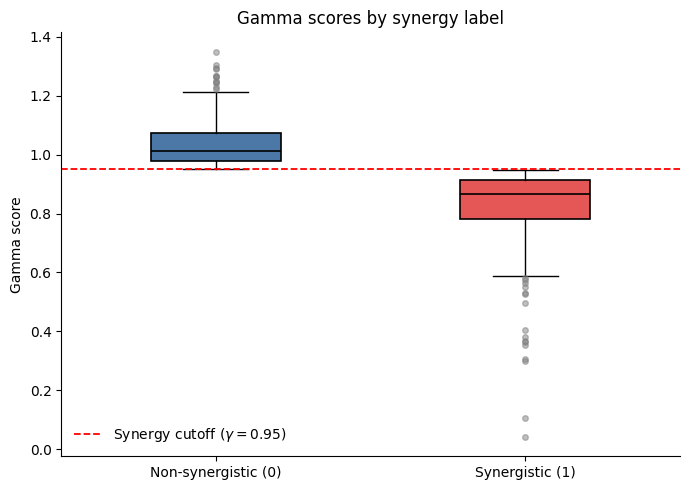

In [12]:
# ------------------------------------------------------------
# Clean and order data
# ------------------------------------------------------------
plot_df = training[["Label", "Gamma"]].copy()
plot_df = plot_df.dropna(subset=["Label", "Gamma"])

plot_df["Label"] = pd.to_numeric(plot_df["Label"], errors="coerce")
plot_df["Gamma"] = pd.to_numeric(plot_df["Gamma"], errors="coerce")
plot_df = plot_df.dropna(subset=["Label", "Gamma"])

plot_df["Label"] = plot_df["Label"].astype(int)

valid_labels = [0, 1]
plot_df = plot_df[plot_df["Label"].isin(valid_labels)].copy()

if plot_df.empty:
    raise RuntimeError("No valid rows remained after cleaning Label and Gamma.")


# ------------------------------------------------------------
# Prepare grouped data
# ------------------------------------------------------------
gamma_non = plot_df.loc[plot_df["Label"] == 0, "Gamma"].to_numpy()
gamma_syn = plot_df.loc[plot_df["Label"] == 1, "Gamma"].to_numpy()

if len(gamma_non) == 0 or len(gamma_syn) == 0:
    raise RuntimeError(
        "Both label groups (0 and 1) must contain data for the boxplot."
    )


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

box = ax.boxplot(
    [gamma_non, gamma_syn],
    positions=[1, 2],
    widths=0.42,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=1.2),
    boxprops=dict(linewidth=1.2, edgecolor="black"),
    whiskerprops=dict(linewidth=1.0, color="black"),
    capprops=dict(linewidth=1.0, color="black"),
    flierprops=dict(
        marker="o",
        markersize=4,
        markerfacecolor="gray",
        markeredgecolor="gray",
        alpha=0.5,
    ),
)

# Match the original colors
colors = ["#4C78A8", "#E45756"]
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)

# Gamma = 0.95 classification threshold
ax.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    linewidth=1.3,
    label=r"Synergy cutoff ($\gamma = 0.95$)",
)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    "Non-synergistic (0)",
    "Synergistic (1)",
])

ax.set_title("Gamma scores by synergy label")
ax.set_xlabel("")
ax.set_ylabel("Gamma score")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="lower left",
)

fig.tight_layout()


## Drug feature representations

- **Identity and mechanism of action (MoA):** one-hot count vectors summed across the two drugs; vocabularies fitted on each training fold.
- **Log AC50:** pair mean and absolute difference (2 features).
- **Morgan-512:** radius 2, per-drug bit vectors combined as mean and absolute difference (1,024 features).
- **Avalon-2048:** salt-stripped molecular fingerprints averaged across the pair (2,048 features).

Every representation is invariant to swapping drug 1 and drug 2.

In [4]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=512)
salt_remover = SaltRemover.SaltRemover()


def compound_fingerprints(smiles):
    molecule = Chem.MolFromSmiles(str(smiles))
    if molecule is None:
        raise ValueError(f"Invalid SMILES in the PANC-1 training set: {smiles!r}")
    morgan = morgan_generator.GetFingerprint(molecule)
    avalon = pyAvalonTools.GetAvalonFP(
        salt_remover.StripMol(molecule, dontRemoveEverything=True), nBits=2048
    )
    morgan_array = np.zeros(512, dtype=np.float32)
    avalon_array = np.zeros(2048, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(morgan, morgan_array)
    DataStructs.ConvertToNumpyArray(avalon, avalon_array)
    return morgan_array, avalon_array


all_smiles = pd.unique(pd.concat(
    [training["Structure 1"], training["Structure 2"]], ignore_index=True
))
fingerprint_cache = {str(smiles): compound_fingerprints(smiles) for smiles in all_smiles}

morgan_1 = np.vstack([fingerprint_cache[str(x)][0] for x in training["Structure 1"]])
morgan_2 = np.vstack([fingerprint_cache[str(x)][0] for x in training["Structure 2"]])
avalon_1 = np.vstack([fingerprint_cache[str(x)][1] for x in training["Structure 1"]])
avalon_2 = np.vstack([fingerprint_cache[str(x)][1] for x in training["Structure 2"]])
ac50 = training[["Log AC50 (M) 1", "Log AC50 (M) 2"]].to_numpy(dtype=np.float32)

numerical_features = {
    "Log AC50": np.column_stack([
        ac50.mean(axis=1), np.abs(ac50[:, 0] - ac50[:, 1])
    ]).astype(np.float32),
    "Morgan": np.column_stack([
        (morgan_1 + morgan_2) / 2, np.abs(morgan_1 - morgan_2)
    ]).astype(np.float32),
    "Avalon": ((avalon_1 + avalon_2) / 2).astype(np.float32),
}
categorical_features = {
    "Identity": (
        training["Sample Name 1"].fillna("<missing>").astype(str).to_numpy(),
        training["Sample Name 2"].fillna("<missing>").astype(str).to_numpy(),
    ),
    "MoA": (
        training["MOA 1"].fillna("<missing>").astype(str).to_numpy(),
        training["MOA 2"].fillna("<missing>").astype(str).to_numpy(),
    ),
}

assert {k: v.shape[1] for k, v in numerical_features.items()} == {
    "Log AC50": 2, "Morgan": 1024, "Avalon": 2048
}
assert all(np.isfinite(x).all() for x in numerical_features.values())

family_order = ("Identity", "MoA", "Log AC50", "Morgan", "Avalon")
family_names = {"Morgan": "Morgan-512", "Avalon": "Avalon-2048"}
feature_subsets = [
    (subset, " + ".join(family_names.get(f, f) for f in subset))
    for r in range(1, len(family_order) + 1)
    for subset in combinations(family_order, r)
]
assert len(feature_subsets) == 31

display(pd.DataFrame({
    "Feature family": family_order,
    "Representation": ["Fold-specific symmetric one-hot counts",
                       "Fold-specific symmetric one-hot counts",
                       "Mean and absolute difference",
                       "Mean and absolute difference",
                       "Element-wise mean"],
    "Numerical dimensions": ["Fold-dependent", "Fold-dependent", 2, 1024, 2048],
}))

,Feature family,Representation,Numerical dimensions
0,Identity,Fold-specific symmetric one-hot counts,Fold-dependent
1,MoA,Fold-specific symmetric one-hot counts,Fold-dependent
2,Log AC50,Mean and absolute difference,2
3,Morgan,Mean and absolute difference,1024
4,Avalon,Element-wise mean,2048


## One-compound-out validation

Each of the 32 drugs defines one held-out round. All combinations containing that drug are excluded from that round's training data. Each unordered drug pair appears in two different test rounds, so the 32 test sets overlap and are **not independent folds**.

In [5]:
splits = []
drug_1 = training["Sample ID 1"].astype(str).to_numpy()
drug_2 = training["Sample ID 2"].astype(str).to_numpy()

for fold, held_out in enumerate(compound_ids, start=1):
    is_test = (drug_1 == held_out) | (drug_2 == held_out)
    train_idx = np.flatnonzero(~is_test)
    test_idx = np.flatnonzero(is_test)
    assert len(train_idx) + len(test_idx) == len(training)
    assert len(np.unique(labels[train_idx])) == 2
    assert len(np.unique(labels[test_idx])) == 2
    splits.append({
        "fold": fold,
        "held_out_compound": held_out,
        "train_idx": train_idx,
        "test_idx": test_idx,
    })

assert len(splits) == 32
assert sum(len(s["test_idx"]) for s in splits) == 2 * len(training)

display(pd.DataFrame([
    {"fold": s["fold"], "held_out_compound": s["held_out_compound"],
     "n_train": len(s["train_idx"]), "n_test": len(s["test_idx"]),
     "positive_test_fraction": labels[s["test_idx"]].mean()}
    for s in splits
]).head())

,fold,held_out_compound,n_train,n_test,positive_test_fraction
0,1,NCGC00015038-08,465,31,0.193548
1,2,NCGC00016268-09,465,31,0.129032
2,3,NCGC00025060-04,465,31,0.129032
3,4,NCGC00182868-16,465,31,0.483871
4,5,NCGC00188382-05,465,31,0.645161


## Hyperparameters

All models use the same 32 held-out-compound rounds and feature subsets. Logistic regression and MLP standardise numerical columns using the training partition only; categorical one-hot counts remain unscaled. The NCATS classifier and Gamma regressor share two fits and yield four prediction outputs.

In [6]:
RANDOM_STATE = 42
NCATS_RANDOM_STATE = 2


def model_factories():
    return {
        "Logistic regression": lambda: LogisticRegression(
            solver="liblinear", max_iter=5000, random_state=RANDOM_STATE
        ),
        "Random forest": lambda: RandomForestClassifier(
            n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "Gradient boosting": lambda: GradientBoostingClassifier(
            random_state=RANDOM_STATE
        ),
        "MLP": lambda: MLPClassifier(
            hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-4,
            learning_rate_init=1e-3, max_iter=1000, early_stopping=True,
            validation_fraction=0.15, random_state=RANDOM_STATE
        ),
        "NCATS RF classifier": lambda: RandomForestClassifier(
            n_estimators=100, random_state=NCATS_RANDOM_STATE, n_jobs=-1
        ),
        "NCATS RF regressor": lambda: RandomForestRegressor(
            n_estimators=100, random_state=NCATS_RANDOM_STATE, n_jobs=-1
        ),
    }


model_names = (
    "Logistic regression", "Random forest", "Gradient boosting", "MLP",
    "NCATS RF classifier", "NCATS RF regressor score", "NCATS RF consensus",
    "NCATS RF consensus (train-range)",
)


def make_encoder():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)


def make_fold_features(subset, train_idx, test_idx, standardise=False):
    train_parts = []
    test_parts = []
    numerical_blocks = [numerical_features[f] for f in subset if f in numerical_features]
    if numerical_blocks:
        matrix = np.column_stack(numerical_blocks)
        train_numeric = matrix[train_idx].copy()
        test_numeric = matrix[test_idx].copy()
        if standardise:
            scaler = StandardScaler()
            train_numeric = scaler.fit_transform(train_numeric)
            test_numeric = scaler.transform(test_numeric)
        train_parts.append(train_numeric)
        test_parts.append(test_numeric)
    for family in ("Identity", "MoA"):
        if family not in subset:
            continue
        left, right = categorical_features[family]
        encoder = make_encoder()
        encoder.fit(np.r_[left[train_idx], right[train_idx]].reshape(-1, 1))
        train_parts.append(
            encoder.transform(left[train_idx].reshape(-1, 1))
            + encoder.transform(right[train_idx].reshape(-1, 1))
        )
        test_parts.append(
            encoder.transform(left[test_idx].reshape(-1, 1))
            + encoder.transform(right[test_idx].reshape(-1, 1))
        )
    x_train = np.column_stack(train_parts).astype(np.float32)
    x_test = np.column_stack(test_parts).astype(np.float32)
    assert x_train.shape[1] == x_test.shape[1]
    assert np.isfinite(x_train).all() and np.isfinite(x_test).all()
    return x_train, x_test


def gamma_synergy_score(predicted_gamma):
    predicted_gamma = np.asarray(predicted_gamma, dtype=float)
    span = np.ptp(predicted_gamma)
    if span == 0:
        return np.full(len(predicted_gamma), 0.5)
    return 1 - (predicted_gamma - predicted_gamma.min()) / span


def gamma_synergy_score_train_range(train_gamma, test_gamma):
    lower, upper = float(np.min(train_gamma)), float(np.max(train_gamma))
    if upper <= lower:
        return np.full(len(test_gamma), 0.5)
    return 1 - np.clip((test_gamma - lower) / (upper - lower), 0, 1)

## Matched model–feature evaluation

The complete analysis fits 31 feature subsets × 32 rounds × 6 estimators = 5,952 estimators. Each NCATS classifier–regressor pair provides four prediction outputs.

In [7]:
fold_rows = []
factories = model_factories()

for subset_index, (subset, feature_name) in enumerate(feature_subsets, start=1):
    print(f"[{subset_index:02d}/{len(feature_subsets)}] {feature_name}", flush=True)
    for split in splits:
        train_idx = split["train_idx"]
        test_idx = split["test_idx"]
        y_train = labels[train_idx]
        y_test = labels[test_idx]
        x_train, x_test = make_fold_features(subset, train_idx, test_idx)
        scores = {}

        for name in ("Random forest", "Gradient boosting"):
            model = factories[name]()
            model.fit(x_train, y_train)
            scores[name] = model.predict_proba(x_test)[:, 1]

        for name in ("Logistic regression", "MLP"):
            scaled_train, scaled_test = make_fold_features(
                subset, train_idx, test_idx, standardise=True
            )
            model = factories[name]()
            model.fit(scaled_train, y_train)
            scores[name] = model.predict_proba(scaled_test)[:, 1]

        ncats_classifier = factories["NCATS RF classifier"]()
        ncats_regressor = factories["NCATS RF regressor"]()
        ncats_classifier.fit(x_train, y_train)
        ncats_regressor.fit(x_train, gamma[train_idx])
        cls_score = ncats_classifier.predict_proba(x_test)[:, 1]
        test_gamma = ncats_regressor.predict(x_test)
        train_gamma = ncats_regressor.predict(x_train)
        reg_score = gamma_synergy_score(test_gamma)
        train_range_score = gamma_synergy_score_train_range(train_gamma, test_gamma)

        scores.update({
            "NCATS RF classifier": cls_score,
            "NCATS RF regressor score": reg_score,
            "NCATS RF consensus": (cls_score + reg_score) / 2,
            "NCATS RF consensus (train-range)": (cls_score + train_range_score) / 2,
        })

        for model_name, score in scores.items():
            fold_rows.append({
                "model": model_name,
                "feature_set": feature_name,
                "fold": split["fold"],
                "held_out_compound": split["held_out_compound"],
                "n_test": len(test_idx),
                "test_prevalence": float(y_test.mean()),
                "roc_auc": roc_auc_score(y_test, score),
                "average_precision": average_precision_score(y_test, score),
            })

fold_metrics = pd.DataFrame(fold_rows)
assert len(fold_metrics) == len(feature_subsets) * len(splits) * len(model_names)
assert not fold_metrics.duplicated(["model", "feature_set", "fold"]).any()

summary = (
    fold_metrics.groupby(["model", "feature_set"], as_index=False)
    .agg(
        n_rounds=("fold", "nunique"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", lambda v: np.std(v, ddof=0)),
        average_precision_mean=("average_precision", "mean"),
        average_precision_sd=("average_precision", lambda v: np.std(v, ddof=0)),
    )
    .sort_values("average_precision_mean", ascending=False)
    .reset_index(drop=True)
)
assert len(summary) == 248
print(f"Completed {len(summary)} configurations across {len(splits)} rounds.")

[01/31] Identity


[02/31] MoA
[03/31] Log AC50
[04/31] Morgan-512
[05/31] Avalon-2048
[06/31] Identity + MoA
[07/31] Identity + Log AC50
[08/31] Identity + Morgan-512
[09/31] Identity + Avalon-2048
[10/31] MoA + Log AC50
[11/31] MoA + Morgan-512
[12/31] MoA + Avalon-2048
[13/31] Log AC50 + Morgan-512
[14/31] Log AC50 + Avalon-2048
[15/31] Morgan-512 + Avalon-2048
[16/31] Identity + MoA + Log AC50
[17/31] Identity + MoA + Morgan-512
[18/31] Identity + MoA + Avalon-2048
[19/31] Identity + Log AC50 + Morgan-512
[20/31] Identity + Log AC50 + Avalon-2048
[21/31] Identity + Morgan-512 + Avalon-2048
[22/31] MoA + Log AC50 + Morgan-512
[23/31] MoA + Log AC50 + Avalon-2048
[24/31] MoA + Morgan-512 + Avalon-2048
[25/31] Log AC50 + Morgan-512 + Avalon-2048
[26/31] Identity + MoA + Log AC50 + Morgan-512
[27/31] Identity + MoA + Log AC50 + Avalon-2048
[28/31] Identity + MoA + Morgan-512 + Avalon-2048
[29/31] Identity + Log AC50 + Morgan-512 + Avalon-2048
[30/31] MoA + Log AC50 + Morgan-512 + Avalon-2048
[31/31] Iden

## NCATS reproduction and model comparison

ROC-AUC and average precision (AP) are calculated separately for each held-out compound and reported as mean ± standard deviation across the 32 overlapping rounds. The prevalence-only reference is not counted among the 248 configurations.

In [ ]:
original_ncats = summary.loc[
    (summary["model"] == "NCATS RF consensus")
    & (summary["feature_set"] == "Avalon-2048")
]
assert len(original_ncats) == 1
print("Published NCATS/PANC-1 reproduction (Avalon-2048, NCATS RF consensus)")
display(original_ncats[[
    "roc_auc_mean", "roc_auc_sd", "average_precision_mean", "average_precision_sd"
]])

best_by_model = (
    summary.sort_values("average_precision_mean", ascending=False)
    .drop_duplicates("model")
    .reset_index(drop=True)
)
print("Highest average precision for each prediction output")
display(best_by_model)

print("Overall highest ROC-AUC configurations")
display(summary.sort_values("roc_auc_mean", ascending=False).head(10))

prevalence_rows = []
for split in splits:
    tr, te = split["train_idx"], split["test_idx"]
    constant = np.full(len(te), float(labels[tr].mean()))
    prevalence_rows.append({
        "fold": split["fold"],
        "roc_auc": roc_auc_score(labels[te], constant),
        "average_precision": average_precision_score(labels[te], constant),
    })
prevalence_metrics = pd.DataFrame(prevalence_rows)
print("Dummy prevalence reference")

display(pd.DataFrame({
    "mean": prevalence_metrics[
        ["roc_auc", "average_precision"]
    ].mean(),
    "std": prevalence_metrics[
        ["roc_auc", "average_precision"]
    ].std(ddof=0)
}))

## Feature-addition comparisons

For each of the eight model outputs, the marginal contribution of a feature family is calculated over the **15 non-empty base feature subsets** not containing it. Positive values indicate improvement after adding that family under the same 32 validation rounds. These are descriptive comparisons, not independent tests.

In [9]:
lookup = {frozenset(subset): name for subset, name in feature_subsets}
performance = summary.set_index(["model", "feature_set"])
contrast_rows = []

for model_name in model_names:
    for subset, base_name in feature_subsets:
        for added in family_order:
            if added in subset:
                continue
            expanded_name = lookup[frozenset(subset) | {added}]
            base = performance.loc[(model_name, base_name)]
            expanded = performance.loc[(model_name, expanded_name)]
            contrast_rows.append({
                "model": model_name,
                "feature_added": added,
                "base_feature_set": base_name,
                "expanded_feature_set": expanded_name,
                "delta_average_precision": (
                    expanded["average_precision_mean"] - base["average_precision_mean"]
                ),
                "delta_roc_auc": expanded["roc_auc_mean"] - base["roc_auc_mean"],
            })

feature_additions = pd.DataFrame(contrast_rows)
assert len(feature_additions) == len(model_names) * len(family_order) * 15

feature_addition_summary = (
    feature_additions.groupby(["model", "feature_added"], as_index=False)
    .agg(
        mean_delta_ap=("delta_average_precision", "mean"),
        ap_improved=("delta_average_precision", lambda v: int((v > 0).sum())),
        n_comparisons=("delta_average_precision", "size"),
        mean_delta_auc=("delta_roc_auc", "mean"),
    )
)
display(feature_addition_summary)

,model,feature_added,mean_delta_ap,ap_improved,n_comparisons,mean_delta_auc
0,Gradient boosting,Avalon,0.020057,7,15,0.029215
1,Gradient boosting,Identity,0.011569,9,15,0.011265
2,Gradient boosting,Log AC50,0.006791,10,15,0.005346
3,Gradient boosting,MoA,0.009882,7,15,0.012207
4,Gradient boosting,Morgan,0.012634,9,15,0.009337
5,Logistic regression,Avalon,0.011664,15,15,0.014085
6,Logistic regression,Identity,0.008496,7,15,0.013124
7,Logistic regression,Log AC50,-0.000167,2,15,0.000556
8,Logistic regression,MoA,0.007063,5,15,0.010265
9,Logistic regression,Morgan,-0.038039,1,15,-0.024712


## Selected thesis benchmark results

The table below reproduces the selection logic of thesis Table 3.1: highest-AP feature set for each prediction output, the highest-ROC-AUC configuration, the original NCATS reproduction and the competitive two-feature random forest. Results are calculated from the current execution rather than loaded from saved summaries.

In [10]:
selected = [
    (row.model, row.feature_set)
    for row in best_by_model.itertuples(index=False)
]
top_auc = summary.sort_values("roc_auc_mean", ascending=False).iloc[0]
selected += [
    (top_auc["model"], top_auc["feature_set"]),
    ("NCATS RF consensus", "Avalon-2048"),
    ("Random forest", "Log AC50 + Morgan-512"),
]
seen = set()
selected = [x for x in selected if not (x in seen or seen.add(x))]

rows = []
for model_name, feature_set in selected:
    item = performance.loc[(model_name, feature_set)]
    rows.append({
        "Model": model_name,
        "Feature set": feature_set,
        "ROC-AUC": f'{item["roc_auc_mean"]:.3f} ± {item["roc_auc_sd"]:.3f}',
        "AP": f'{item["average_precision_mean"]:.3f} ± {item["average_precision_sd"]:.3f}',
        "AP mean": item["average_precision_mean"],
    })
selected_results = pd.DataFrame(rows).sort_values("AP mean", ascending=False)
display(selected_results.drop(columns="AP mean").reset_index(drop=True))

,Model,Feature set,ROC-AUC,AP
0,Random forest,MoA + Log AC50 + Morgan-512 + Avalon-2048,0.779 ± 0.099,0.787 ± 0.157
1,Random forest,Log AC50 + Morgan-512,0.774 ± 0.112,0.786 ± 0.163
2,Gradient boosting,Identity + MoA + Log AC50 + Avalon-2048,0.778 ± 0.102,0.783 ± 0.148
3,NCATS RF regressor score,Morgan-512 + Avalon-2048,0.783 ± 0.100,0.780 ± 0.183
4,NCATS RF consensus,Identity + Log AC50 + Morgan-512 + Avalon-2048,0.786 ± 0.095,0.778 ± 0.178
5,NCATS RF consensus (train-range),Identity + MoA + Morgan-512 + Avalon-2048,0.783 ± 0.101,0.775 ± 0.182
6,NCATS RF consensus,Log AC50 + Avalon-2048,0.793 ± 0.082,0.774 ± 0.183
7,NCATS RF classifier,Identity + MoA + Log AC50 + Morgan-512,0.769 ± 0.107,0.773 ± 0.166
8,NCATS RF consensus,Avalon-2048,0.782 ± 0.086,0.764 ± 0.188
9,Logistic regression,Avalon-2048,0.739 ± 0.168,0.760 ± 0.221
